# Notebook 04 - Transformer (Graph-Attention) VAE and comparison to the baseline

**Purpose.** Notebook 03 builds the baseline generative pipeline with a `GraphVAE` whose encoder uses **GINEConv** message passing. Here we test the "add a transformer" suggestion in its lightest, lowest-risk form (**tier 1**): we keep Notebook 03 unchanged and add a *drop-in* encoder that replaces the GINEConv layers with **multi-head graph attention** (`TransformerConv`). The decoder, loss, training loop, beta schedule and evaluation code are reused verbatim, so any difference is attributable to the encoder.

**How it works.** The first code cell `%run`s Notebook 03, which trains the baseline and brings all of its classes, helpers, the `config`, the data loaders and the generation/evaluation functions into this kernel. We then subclass the baseline `GraphVAE`, swap in the attention encoder, train it under identical settings, and compare the two.

> Encoder-level change after Nguyen & Karolak (2025), *Transformer graph variational autoencoder for generative molecular design* (Biophysical Journal, doi:10.1016/j.bpj.2025.01.022). The full TGVAE also replaces the graph decoder with an autoregressive SMILES transformer, which is a larger change left as future work.

In [5]:
# Standalone bootstrap: shared imports, checkpoint loading, and helper functions
from pathlib import Path
import copy
import json
import os
import random
import sys

import importlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from rdkit import Chem
from rdkit.Chem import Crippen, Descriptors, QED, RWMol, rdMolDescriptors
from torch.utils.data import random_split
from torch_geometric.loader import DataLoader
from torch_geometric.nn import global_mean_pool, TransformerConv
from torch_geometric.utils import to_dense_adj, to_dense_batch

project_root = Path.cwd()
for candidate in (Path.cwd(), Path.cwd() / 'src', Path.cwd().parent / 'src'):
    if (candidate / 'core' / 'vae_architecture.py').exists():
        project_root = candidate
        break
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from core.vae_architecture import GraphEncoder, GraphDecoder

config = {
    'node_features': 8,
    'edge_features': 5,
    'global_features': 2,
    'hidden_dim': 128,
    'latent_dim': 64,
    'num_layers': 3,
    'dropout': 0.2,
    'pocket_dim': 128,
    'max_nodes': 50,
    'beta': 1e-4,
    'use_pocket': True,
}

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'

def _autocast():
    if USE_AMP:
        return torch.amp.autocast('cuda')
    import contextlib
    return contextlib.nullcontext()

def _find_existing_path(*relative_paths):
    for relative_path in relative_paths:
        candidate = Path(relative_path)
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f'None of these paths exist: {relative_paths}')

scaler_path = _find_existing_path('node_feature_scaler.pt', '../data/processed/node_feature_scaler.pt', 'data/processed/node_feature_scaler.pt')
data_path = _find_existing_path('../data/processed/graph_data.pt', 'data/processed/graph_data.pt')
checkpoint_path = _find_existing_path('graph_vae_egfr_stable.pth', '../src/graph_vae_egfr_stable.pth', 'src/graph_vae_egfr_stable.pth', '../models/egfr_finetuned_graphvae.pth', 'models/egfr_finetuned_graphvae.pth')
scaler = torch.load(scaler_path, map_location='cpu')
X_MEAN = scaler['x_mean']
X_STD = scaler['x_std']

def load_and_prepare_data(filepath, batch_size=32, seed=42):
    container = torch.load(filepath, weights_only=False)
    dataset = container['graphs']
    total_size = len(dataset)
    train_size = int(0.8 * total_size)
    val_size = total_size - train_size
    generator = torch.Generator().manual_seed(seed)
    train_ds, val_ds = random_split(dataset, [train_size, val_size], generator=generator)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    print(f'Dataset  : {total_size} graphs  |  train {train_size}  val {val_size}')
    return train_loader, val_loader

train_loader, val_loader = load_and_prepare_data(data_path)

class GraphVAE(nn.Module):
    def __init__(self, **kwargs):
        super().__init__()
        self.beta = kwargs.get('beta', 1e-4)
        self.latent_dim = kwargs.get('latent_dim', 64)
        encoder_kwargs = {
            'node_features': kwargs.get('node_features', 8),
            'edge_features': kwargs.get('edge_features', 5),
            'global_features': kwargs.get('global_features', 2),
            'hidden_dim': kwargs.get('hidden_dim', 128),
            'latent_dim': kwargs.get('latent_dim', 64),
            'num_layers': kwargs.get('num_layers', 3),
            'dropout': kwargs.get('dropout', 0.2),
        }
        decoder_kwargs = {
            'latent_dim': kwargs.get('latent_dim', 64),
            'hidden_dim': kwargs.get('hidden_dim', 128),
            'pocket_dim': kwargs.get('pocket_dim', 133),
            'max_nodes': kwargs.get('max_nodes', 50),
            'node_features': kwargs.get('node_features', 8),
            'edge_features': kwargs.get('edge_features', 5),
            'dropout': kwargs.get('dropout', 0.2),
            'use_pocket': kwargs.get('use_pocket', True),
        }
        self.encoder = GraphEncoder(**encoder_kwargs)
        self.decoder = GraphDecoder(**decoder_kwargs)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x, edge_index, edge_attr, batch, global_features, pocket_embedding=None):
        if global_features.dim() == 1:
            global_features = global_features.view(batch.max().item() + 1, -1)
        global_features = global_features[:, :2]
        if pocket_embedding is not None and pocket_embedding.dim() == 1:
            pocket_embedding = pocket_embedding.view(batch.max().item() + 1, -1)
        mu, logvar = self.encoder(x, edge_index, edge_attr, batch, global_features)
        z = self.reparameterize(mu, logvar)
        node_logits, adj_logits, type_logits = self.decoder(z, pocket_embedding)
        node_logits = torch.clamp(node_logits, -20., 20.)
        adj_logits = torch.clamp(adj_logits, -20., 20.)
        type_logits = torch.clamp(type_logits, -20., 20.)
        return node_logits, adj_logits, type_logits, mu, logvar

    def loss_function(self, dense_x, dense_adj, dense_edge_attr, node_logits, adj_logits, type_logits, mu, logvar):
        node_mask = (dense_x.abs().sum(dim=-1) > 0)
        if node_mask.any():
            recon_node = F.mse_loss(node_logits[node_mask], dense_x[node_mask], reduction='mean')
        else:
            recon_node = torch.tensor(0.0, device=dense_x.device)
        n_pos = dense_adj.sum().clamp(min=1)
        n_neg = (1.0 - dense_adj).sum().clamp(min=1)
        pos_weight = torch.tensor((n_neg / n_pos).clamp(max=50).item(), device=dense_adj.device)
        recon_adj = F.binary_cross_entropy_with_logits(adj_logits, dense_adj, pos_weight=pos_weight, reduction='mean')
        bond_mask = dense_adj.bool()
        if bond_mask.any():
            pred_types = type_logits[bond_mask]
            true_types = dense_edge_attr[bond_mask].float()
            recon_type = F.binary_cross_entropy_with_logits(pred_types, true_types, reduction='mean')
        else:
            recon_type = torch.tensor(0.0, device=dense_x.device)
        recon_loss = recon_node + recon_adj + recon_type
        logvar = torch.clamp(logvar, min=-10, max=4)
        kl_per_dim = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp())
        kl_per_dim = torch.clamp(kl_per_dim, min=0.1)
        kl_loss = kl_per_dim.mean()
        total_loss = recon_loss + self.beta * kl_loss
        return total_loss, recon_loss, kl_loss

def _load_baseline_model():
    baseline = GraphVAE(**config).to(device)
    state_dict = torch.load(checkpoint_path, map_location=device)
    if isinstance(state_dict, dict) and any(key.startswith('encoder.') for key in state_dict.keys()):
        baseline.load_state_dict(state_dict)
    else:
        baseline.load_state_dict(state_dict)
    baseline.eval()
    return baseline

baseline_model = _load_baseline_model()
model = baseline_model

@torch.no_grad()
def evaluate_epoch(model, loader):
    model.eval()
    totals = {'loss': 0.0, 'recon': 0.0, 'kl': 0.0}
    n_batches = 0
    for batch in loader:
        batch = batch.to(device)
        with _autocast():
            node_logits, adj_logits, type_logits, mu, logvar = model(
                batch.x, batch.edge_index, batch.edge_attr, batch.batch, batch.global_features, batch.pocket_embedding
            )
            dense_adj = to_dense_adj(batch.edge_index, batch.batch, max_num_nodes=config['max_nodes'])
            dense_x, _ = to_dense_batch(batch.x, batch.batch, max_num_nodes=config['max_nodes'])
            dense_edge_attr = to_dense_adj(batch.edge_index, batch.batch, edge_attr=batch.edge_attr.float(), max_num_nodes=config['max_nodes'])
            loss, recon, kl = model.loss_function(
                dense_x, dense_adj, dense_edge_attr, node_logits, adj_logits, type_logits, mu, logvar
            )
        totals['loss'] += loss.item()
        totals['recon'] += recon.item()
        totals['kl'] += kl.item()
        n_batches += 1
    n_batches = max(n_batches, 1)
    return {key: value / n_batches for key, value in totals.items()}

baseline_summary = evaluate_epoch(baseline_model, val_loader)
print(f"Loaded baseline checkpoint: {checkpoint_path.name}")
print(f"Baseline validation summary | loss {baseline_summary['loss']:.4f} | recon {baseline_summary['recon']:.4f} | kl {baseline_summary['kl']:.4f}")

NUM_EPOCHS = 125
TARGET_BETA = 0.005
WARMUP_EPOCHS = 80

def get_beta(epoch):
    if epoch < 5:
        return 0.0
    ramp = (epoch - 5) / max(1, WARMUP_EPOCHS)
    return min(TARGET_BETA, TARGET_BETA * ramp)

def train_epoch(model, loader, optimizer, scaler):
    model.train()
    t_loss = t_recon = t_kl = 0.0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad(set_to_none=True)
        with _autocast():
            node_logits, adj_logits, type_logits, mu, logvar = model(
                batch.x, batch.edge_index, batch.edge_attr, batch.batch, batch.global_features, batch.pocket_embedding
            )
            dense_adj = to_dense_adj(batch.edge_index, batch.batch, max_num_nodes=config['max_nodes'])
            dense_x, _ = to_dense_batch(batch.x, batch.batch, max_num_nodes=config['max_nodes'])
            dense_edge_attr = to_dense_adj(batch.edge_index, batch.batch, edge_attr=batch.edge_attr.float(), max_num_nodes=config['max_nodes'])
            loss, recon, kl = model.loss_function(dense_x, dense_adj, dense_edge_attr, node_logits, adj_logits, type_logits, mu, logvar)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        t_loss += loss.item(); t_recon += recon.item(); t_kl += kl.item()
    n = max(len(loader), 1)
    return t_loss / n, t_recon / n, t_kl / n

def val_epoch(model, loader):
    model.eval()
    v_loss = v_recon = v_kl = 0.0
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            with _autocast():
                node_logits, adj_logits, type_logits, mu, logvar = model(
                    batch.x, batch.edge_index, batch.edge_attr, batch.batch, batch.global_features, batch.pocket_embedding
                )
                dense_adj = to_dense_adj(batch.edge_index, batch.batch, max_num_nodes=config['max_nodes'])
                dense_x, _ = to_dense_batch(batch.x, batch.batch, max_num_nodes=config['max_nodes'])
                dense_edge_attr = to_dense_adj(batch.edge_index, batch.batch, edge_attr=batch.edge_attr.float(), max_num_nodes=config['max_nodes'])
                loss, recon, kl = model.loss_function(dense_x, dense_adj, dense_edge_attr, node_logits, adj_logits, type_logits, mu, logvar)
            v_loss += loss.item(); v_recon += recon.item(); v_kl += kl.item()
    n = max(len(loader), 1)
    return v_loss / n, v_recon / n, v_kl / n

MAX_VALENCE = {6: 4, 7: 3, 8: 2, 9: 1, 15: 5, 16: 2, 17: 1, 35: 1, 53: 1}
SAFE_BOND_TYPES = [
    Chem.rdchem.BondType.SINGLE,
    Chem.rdchem.BondType.DOUBLE,
    Chem.rdchem.BondType.SINGLE,
    Chem.rdchem.BondType.SINGLE,
]

def _snap_atomic_num(value):
    candidates = np.array([6, 7, 8, 9, 15, 16, 17, 35, 53])
    return int(candidates[np.argmin(np.abs(candidates - round(float(value))))])

def decoded_graph_to_smiles(node_logits_i, adj_logits_i, type_logits_i, adj_threshold=0.75):
    node_vals = node_logits_i.cpu().float().numpy()
    adj_probs = torch.sigmoid(adj_logits_i).cpu().numpy()
    type_arr = type_logits_i.cpu().numpy()
    adj_binary = (adj_probs >= adj_threshold)
    adj_binary = adj_binary | adj_binary.T
    has_bond = adj_binary.sum(axis=1) > 0
    active_idx = np.where(has_bond)[0]
    if len(active_idx) < 2 or len(active_idx) > 45:
        return None
    node_vals_denorm = node_vals * X_STD.numpy() + X_MEAN.numpy()
    atomic_nums_raw = node_vals_denorm[:, 0]
    try:
        rw = RWMol()
        idx_map = {}
        remaining_valence = {}
        for g_idx in active_idx:
            an = _snap_atomic_num(atomic_nums_raw[g_idx])
            fc = int(np.clip(round(float(node_vals_denorm[g_idx, 2])), -1, 1))
            atom = Chem.Atom(an)
            atom.SetFormalCharge(fc)
            mol_idx = rw.AddAtom(atom)
            idx_map[g_idx] = mol_idx
            remaining_valence[mol_idx] = MAX_VALENCE.get(an, 4) + max(0, fc)
        bond_candidates = []
        for ii, i in enumerate(active_idx):
            for j in active_idx[ii + 1:]:
                p = float(adj_probs[i, j])
                if p >= adj_threshold:
                    bt = int(np.argmax(type_arr[i, j, :4]))
                    bond_order = 2 if bt == 1 else 1
                    bond_candidates.append((p, i, j, bt, bond_order))
        bond_candidates.sort(reverse=True)
        for p, i, j, bt, order in bond_candidates:
            mi, mj = idx_map[i], idx_map[j]
            if remaining_valence[mi] >= order and remaining_valence[mj] >= order:
                rw.AddBond(mi, mj, SAFE_BOND_TYPES[bt])
                remaining_valence[mi] -= order
                remaining_valence[mj] -= order
        mol = rw.GetMol()
        Chem.SanitizeMol(mol)
        return Chem.MolToSmiles(mol, canonical=True)
    except Exception:
        return None

def sa_score(mol):
    try:
        from rdkit.Chem import RDConfig
        sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score'))
        sascorer = importlib.import_module('sascorer')
        return sascorer.calculateScore(mol)
    except Exception:
        n_atoms = mol.GetNumAtoms()
        if n_atoms == 0:
            return 10.0
        ring_n = Chem.rdMolDescriptors.CalcNumRings(mol)
        return max(1.0, min(10.0, 1.0 + 9.0 * ring_n / n_atoms))

def evaluate_molecule(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    mw = Descriptors.MolWt(mol)
    logp = Crippen.MolLogP(mol)
    hbd = Descriptors.NumHDonors(mol)
    hba = Descriptors.NumHAcceptors(mol)
    return {
        'SMILES': smiles,
        'QED': round(QED.qed(mol), 4),
        'SA_score': round(sa_score(mol), 3),
        'MW': round(mw, 2),
        'LogP': round(logp, 3),
        'HBD': hbd,
        'HBA': hba,
        'Lipinski_pass': int(mw < 500 and logp < 5 and hbd < 5 and hba < 10),
        'Aromatic_rings': Chem.rdMolDescriptors.CalcNumAromaticRings(mol),
        'NumAtoms': mol.GetNumHeavyAtoms(),
    }

def is_egfr_viable(smiles):
    if '.' in smiles:
        return False
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return False
    if rdMolDescriptors.CalcNumAromaticRings(mol) < 1:
        return False
    ha = mol.GetNumHeavyAtoms()
    if ha < 15 or ha > 55:
        return False
    f_count = sum(1 for atom in mol.GetAtoms() if atom.GetAtomicNum() == 9)
    if f_count > 6:
        return False
    if Descriptors.MolWt(mol) > 600:
        return False
    return True

print('Notebook 04 bootstrap complete.')

Dataset  : 19846 graphs  |  train 15876  val 3970
Loaded baseline checkpoint: graph_vae_egfr_stable.pth
Baseline validation summary | loss 1.7804 | recon 1.7800 | kl 3.7526
Notebook 04 bootstrap complete.


In [6]:
# Baseline checkpoint was loaded in the bootstrap cell above.
baseline_model = model
print("Baseline checkpoint loaded | final validation summary:",
      f"loss {baseline_summary['loss']:.4f}",
      f"recon {baseline_summary['recon']:.4f}",
      f"kl {baseline_summary['kl']:.4f}")

Baseline checkpoint loaded | final validation summary: loss 1.7804 recon 1.7800 kl 3.7526


## The transformer encoder (tier-1 change)

`GraphAttentionEncoder` is a drop-in replacement for the baseline `GraphEncoder`: same constructor keyword arguments, same `forward` signature, same `(mu, logvar)` output. The only difference is that the three `GINEConv` layers (fixed sum-aggregation) are replaced by three `TransformerConv` layers, which let each atom **attend** over its neighbours with learned multi-head attention weights. Edge features are injected through `edge_dim`, exactly as the baseline feeds edge attributes into `GINEConv`.

`GraphVAETransformer` subclasses the Notebook-03 `GraphVAE` and swaps only the encoder, inheriting the identical decoder, reparameterisation, `forward()` and `loss_function()`.

In [7]:
# Attention encoder + VAE variant
from torch_geometric.nn import TransformerConv

class GraphAttentionEncoder(nn.Module):
    """Drop-in replacement for the baseline GraphEncoder.

    Identical constructor kwargs, forward signature and (mu, logvar) output; the
    3 GINEConv message-passing layers are replaced by 3 multi-head graph-attention
    layers (TransformerConv). Edge features enter via edge_dim, mirroring the
    baseline's use of edge attributes inside GINEConv.
    """
    def __init__(self, node_features=8, edge_features=5, global_features=2,
                 hidden_dim=128, latent_dim=64, num_layers=3, dropout=0.2,
                 heads=4, **kwargs):
        super().__init__()
        assert hidden_dim % heads == 0, "hidden_dim must be divisible by heads"
        self.node_encoder = nn.Linear(node_features, hidden_dim)
        self.edge_encoder = nn.Linear(edge_features, hidden_dim)
        # concat=True (default): out = heads * (hidden_dim // heads) = hidden_dim
        self.convs = nn.ModuleList([
            TransformerConv(hidden_dim, hidden_dim // heads, heads=heads,
                            edge_dim=hidden_dim, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.dropout    = nn.Dropout(dropout)
        self.latent_dim = latent_dim
        input_dim = hidden_dim + global_features
        self.to_mu     = nn.Linear(input_dim, latent_dim)
        self.to_logvar = nn.Linear(input_dim, latent_dim)

    def forward(self, x, edge_index, edge_attr, batch, global_features):
        x         = F.relu(self.node_encoder(x))
        edge_attr = F.relu(self.edge_encoder(edge_attr))
        for conv in self.convs:
            x = F.relu(conv(x, edge_index, edge_attr))   # attention message passing
            x = self.dropout(x)
        graph_emb = global_mean_pool(x, batch)           # [B, hidden_dim]
        bs = graph_emb.size(0)
        gf = global_features.float()
        if gf.dim() == 1:                                # DataLoader flattens [B*20]
            gf = gf.view(bs, -1)
        gf = gf[:, :2]                                   # keep first 2 components
        graph_emb = torch.cat([graph_emb, gf], dim=-1)   # [B, hidden_dim + 2]
        mu     = torch.clamp(self.to_mu(graph_emb),     -20.0, 20.0)
        logvar = torch.clamp(self.to_logvar(graph_emb), -10.0,  4.0)
        return mu, logvar


class GraphVAETransformer(GraphVAE):
    """Baseline GraphVAE with the attention encoder swapped in. Inherits the
    SAME decoder, reparameterise, forward() and loss_function() from NB03."""
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.encoder = GraphAttentionEncoder(**kwargs)


def _n_params(m):
    return sum(p.numel() for p in m.parameters())

_probe = GraphVAETransformer(**config)
print(f"Baseline    params: {_n_params(baseline_model):,}")
print(f"Transformer params: {_n_params(_probe):,}")
del _probe

Baseline    params: 2,145,640
Transformer params: 2,293,864


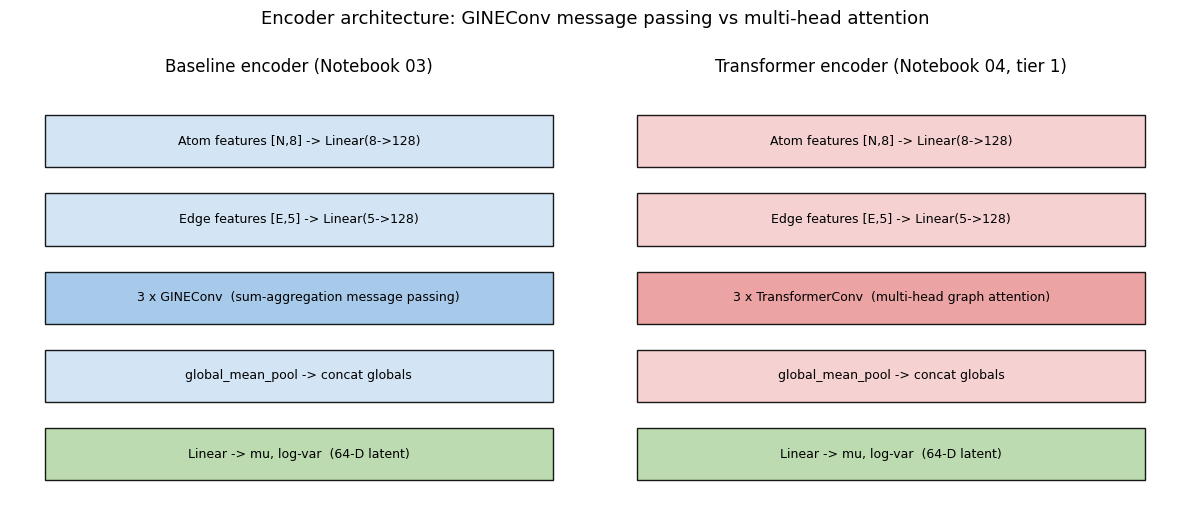

In [8]:
# Architecture schematic (no training needed)
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def _stack(ax, title, rows):
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off'); ax.set_title(title, fontsize=12)
    for y, text, color in rows:
        ax.add_patch(Rectangle((0.06, y), 0.88, 0.12, facecolor=color,
                               edgecolor='black', alpha=0.9))
        ax.text(0.5, y + 0.06, text, ha='center', va='center', fontsize=9)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
_stack(axes[0], 'Baseline encoder (Notebook 03)', [
    (0.80, 'Atom features [N,8] -> Linear(8->128)', '#cfe2f3'),
    (0.62, 'Edge features [E,5] -> Linear(5->128)', '#cfe2f3'),
    (0.44, '3 x GINEConv  (sum-aggregation message passing)', '#9fc5e8'),
    (0.26, 'global_mean_pool -> concat globals', '#cfe2f3'),
    (0.08, 'Linear -> mu, log-var  (64-D latent)', '#b6d7a8'),
])
_stack(axes[1], 'Transformer encoder (Notebook 04, tier 1)', [
    (0.80, 'Atom features [N,8] -> Linear(8->128)', '#f4cccc'),
    (0.62, 'Edge features [E,5] -> Linear(5->128)', '#f4cccc'),
    (0.44, '3 x TransformerConv  (multi-head graph attention)', '#ea9999'),
    (0.26, 'global_mean_pool -> concat globals', '#f4cccc'),
    (0.08, 'Linear -> mu, log-var  (64-D latent)', '#b6d7a8'),
])
fig.suptitle('Encoder architecture: GINEConv message passing vs multi-head attention',
             y=1.0, fontsize=13)
fig.tight_layout()
fig.savefig('../results/figures/nb04_encoder_architecture.png', dpi=300, bbox_inches='tight')
plt.show()

## Train the transformer VAE (identical settings)

Same `config`, optimiser (Adam, lr 1e-3, weight decay 1e-5), cosine schedule, `NUM_EPOCHS` and `get_beta` schedule as the baseline, reusing the Notebook-03 `train_epoch` / `val_epoch`.

**Fairness note.** Notebook 03 does not fix a random seed, so the baseline reflects one unseeded run. For a strictly controlled comparison, add the same `set_seed()` call before the baseline training loop in Notebook 03. Here we seed the transformer run for reproducibility.

In [9]:
# Train the transformer variant under identical settings
import numpy as np, random

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

set_seed(SEED)
tvae = GraphVAETransformer(**config).to(device)
opt  = torch.optim.Adam(tvae.parameters(), lr=1e-3, weight_decay=1e-5)
sch  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=150, eta_min=1e-6)

if USE_AMP:
    tscaler = torch.amp.GradScaler('cuda')
else:
    tscaler = scaler   # reuse the no-op scaler defined in NB03 for CPU

t_train = {'loss': [], 'recon': [], 'kl': []}
t_val   = {'loss': [], 'recon': [], 'kl': []}

for epoch in range(NUM_EPOCHS):
    tvae.beta = get_beta(epoch)                      # identical beta schedule
    tl, tr, tk = train_epoch(tvae, train_loader, opt, tscaler)
    vl, vr, vk = val_epoch(tvae, val_loader)
    t_train['loss'].append(tl); t_train['recon'].append(tr); t_train['kl'].append(tk)
    t_val['loss'].append(vl);   t_val['recon'].append(vr);   t_val['kl'].append(vk)
    sch.step()
    if epoch % 5 == 0 or epoch == NUM_EPOCHS - 1:
        print(f"[Transformer] Epoch {epoch:3d} | beta={tvae.beta:.5f} | "
              f"Train {tl:.4f} (rec {tr:.4f}, kl {tk:.4f}) | "
              f"Val {vl:.4f} (rec {vr:.4f}, kl {vk:.4f})")

torch.save(tvae.state_dict(), '../models/graph_vae_transformer.pth')
print("\nTransformer VAE weights saved -> ../models/graph_vae_transformer.pth")

[Transformer] Epoch   0 | beta=0.00000 | Train 1.8566 (rec 1.8566, kl 115.1546) | Val 1.7190 (rec 1.7190, kl 102.5936)
[Transformer] Epoch   5 | beta=0.00000 | Train 1.6510 (rec 1.6510, kl 90.3871) | Val 1.6375 (rec 1.6375, kl 89.3922)
[Transformer] Epoch  10 | beta=0.00031 | Train 1.6293 (rec 1.6100, kl 61.7236) | Val 1.6092 (rec 1.5898, kl 61.9774)
[Transformer] Epoch  15 | beta=0.00063 | Train 1.5995 (rec 1.5727, kl 42.8338) | Val 1.5796 (rec 1.5548, kl 39.6963)
[Transformer] Epoch  20 | beta=0.00094 | Train 1.5630 (rec 1.5398, kl 24.6902) | Val 1.5625 (rec 1.5398, kl 24.2584)
[Transformer] Epoch  25 | beta=0.00125 | Train 1.5399 (rec 1.5162, kl 18.9507) | Val 1.5195 (rec 1.4960, kl 18.7767)
[Transformer] Epoch  30 | beta=0.00156 | Train 1.5141 (rec 1.4919, kl 14.2225) | Val 1.5255 (rec 1.5026, kl 14.6402)
[Transformer] Epoch  35 | beta=0.00187 | Train 1.4979 (rec 1.4744, kl 12.5211) | Val 1.4918 (rec 1.4686, kl 12.4219)
[Transformer] Epoch  40 | beta=0.00219 | Train 1.4843 (rec 1.4

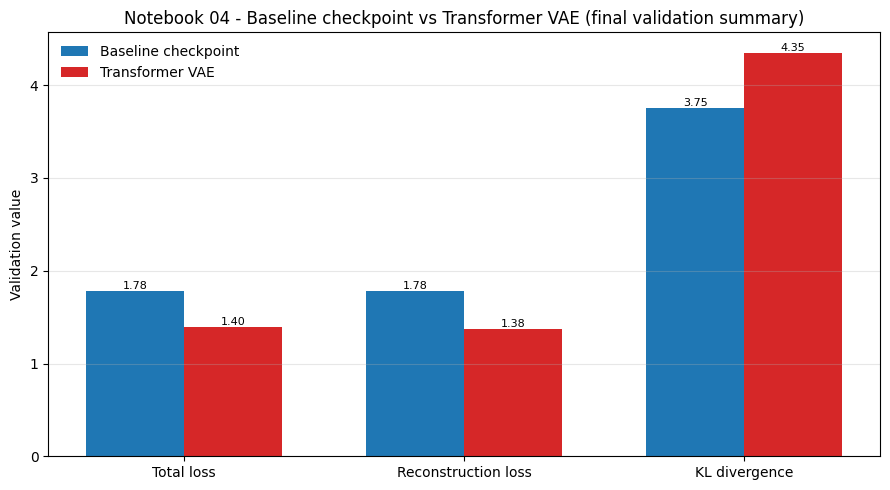

In [10]:
# Figure: baseline checkpoint vs transformer final validation summary
t_final = {'loss': t_val['loss'][-1], 'recon': t_val['recon'][-1], 'kl': t_val['kl'][-1]}
labels = ['Total loss', 'Reconstruction loss', 'KL divergence']
baseline_vals = [baseline_summary['loss'], baseline_summary['recon'], baseline_summary['kl']]
transformer_vals = [t_final['loss'], t_final['recon'], t_final['kl']]
x = np.arange(len(labels))
w = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - w/2, baseline_vals, w, label='Baseline checkpoint', color='#1f77b4')
ax.bar(x + w/2, transformer_vals, w, label='Transformer VAE', color='#d62728')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('Validation value')
ax.set_title('Notebook 04 - Baseline checkpoint vs Transformer VAE (final validation summary)')
ax.grid(axis='y', alpha=0.3)
ax.legend(frameon=False)
for idx, value in enumerate(baseline_vals):
    ax.text(idx - w/2, value, f'{value:.2f}', ha='center', va='bottom', fontsize=8)
for idx, value in enumerate(transformer_vals):
    ax.text(idx + w/2, value, f'{value:.2f}', ha='center', va='bottom', fontsize=8)
fig.tight_layout()
fig.savefig('../results/figures/nb04_training_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Compare generative behaviour

To isolate the effect of the encoder, both models are sampled the same way: draw `z ~ N(0, I)` from the prior and decode with the model's own (jointly trained) decoder, using the identical `decoded_graph_to_smiles` logic from Notebook 03. (Notebook 03's headline generation additionally routes the prior through the LatentGAN; here we compare the VAEs directly so the only variable is the encoder.) We report validity, uniqueness, internal diversity (mean pairwise Tanimoto distance), mean QED and Lipinski pass rate.

In [11]:
# Generate from both VAEs by prior sampling and compute metrics
import numpy as np, random, pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

@torch.no_grad()
def generate_from_vae(vae, n=2000, batch=64, seed=0):
    """Sample z ~ N(0, I), decode with the VAE decoder, return valid SMILES.
    Same decoder + decoding logic for every model, so differences reflect the
    encoder and its jointly-trained latent space, not the sampling method."""
    torch.manual_seed(seed)
    vae.eval()
    smiles, done = [], 0
    while done < n:
        bs = min(batch, n - done)
        z  = torch.randn(bs, config['latent_dim'], device=device)
        pocket = torch.zeros(bs, config['pocket_dim'], device=device)
        node_l, adj_l, type_l = vae.decoder(z, pocket)
        for i in range(bs):
            smi = decoded_graph_to_smiles(node_l[i], adj_l[i], type_l[i])
            if smi:
                smiles.append(smi)
        done += bs
    return smiles

def internal_diversity(smiles, sample=500, seed=0):
    mols = [Chem.MolFromSmiles(s) for s in set(smiles)]
    mols = [m for m in mols if m is not None]
    if len(mols) < 2:
        return float('nan')
    if len(mols) > sample:
        mols = random.Random(seed).sample(mols, sample)
    fps = [AllChem.GetMorganFingerprintAsBitVect(m, 2, 1024) for m in mols]
    sims = []
    for i in range(len(fps)):
        sims.extend(DataStructs.BulkTanimotoSimilarity(fps[i], fps[i+1:]))
    return float(1.0 - np.mean(sims)) if sims else float('nan')

def summarise(name, smiles, n_sampled):
    valid = [s for s in smiles if Chem.MolFromSmiles(s) is not None]
    uniq  = set(valid)
    evals = [evaluate_molecule(s) for s in uniq]
    evals = [e for e in evals if e is not None]
    qed = float(np.mean([e['QED'] for e in evals])) if evals else float('nan')
    lip = float(np.mean([e['Lipinski_pass'] for e in evals])) if evals else float('nan')
    return {
        'model'         : name,
        'n_sampled'     : n_sampled,
        'validity'      : len(valid) / n_sampled,
        'uniqueness'    : (len(uniq) / len(valid)) if valid else float('nan'),
        'int_diversity' : internal_diversity(valid),
        'mean_QED'      : qed,
        'lipinski_rate' : lip,
    }

N_GEN = 2000
base_smiles = generate_from_vae(baseline_model, n=N_GEN, seed=0)
tf_smiles   = generate_from_vae(tvae,           n=N_GEN, seed=0)

cmp = pd.DataFrame([
    summarise('Baseline (GINEConv)',     base_smiles, N_GEN),
    summarise('Transformer (attention)', tf_smiles,   N_GEN),
])
cmp['final_val_loss']  = [baseline_summary['loss'],  t_val['loss'][-1]]
cmp['final_val_recon'] = [baseline_summary['recon'], t_val['recon'][-1]]
cmp['final_val_kl']    = [baseline_summary['kl'],    t_val['kl'][-1]]
cmp.to_csv('../results/nb04_encoder_comparison.csv', index=False)
cmp.round(4)

[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerator
[12:17:00] DEPRECATION WARNING: please use MorganGenerat

,model,n_sampled,validity,uniqueness,int_diversity,mean_QED,lipinski_rate,final_val_loss,final_val_recon,final_val_kl
0,Baseline (GINEConv),2000,0.9635,0.6663,0.5500,0.0582,0.0553,1.7804,1.7800,3.7526
1,Transformer (attention),2000,0.8775,0.5419,0.7226,0.1277,0.1714,1.3976,1.3758,4.3520


In [ ]:
# Figure: generative metrics, baseline vs transformer
metrics = ['validity', 'uniqueness', 'int_diversity', 'lipinski_rate', 'mean_QED']
labels  = ['Validity', 'Uniqueness', 'Int. diversity', 'Lipinski rate', 'Mean QED']
base_vals = [cmp.loc[0, m] for m in metrics]
tf_vals   = [cmp.loc[1, m] for m in metrics]

x = np.arange(len(metrics)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - w/2, base_vals, w, label='Baseline (GINEConv)', color='#1f77b4')
ax.bar(x + w/2, tf_vals,   w, label='Transformer (attention)', color='#d62728')
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=15)
ax.set_ylabel('Value (0-1 scale)'); ax.set_ylim(0, 1)
ax.set_title('Notebook 04 - Generative metrics: baseline vs transformer')
ax.legend(frameon=False); ax.grid(axis='y', alpha=0.3)
for i, (b, t) in enumerate(zip(base_vals, tf_vals)):
    ax.text(i - w/2, b + 0.02, f'{b:.2f}', ha='center', fontsize=8)
    ax.text(i + w/2, t + 0.02, f'{t:.2f}', ha='center', fontsize=8)
fig.tight_layout()
fig.savefig('../results/figures/nb04_generation_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

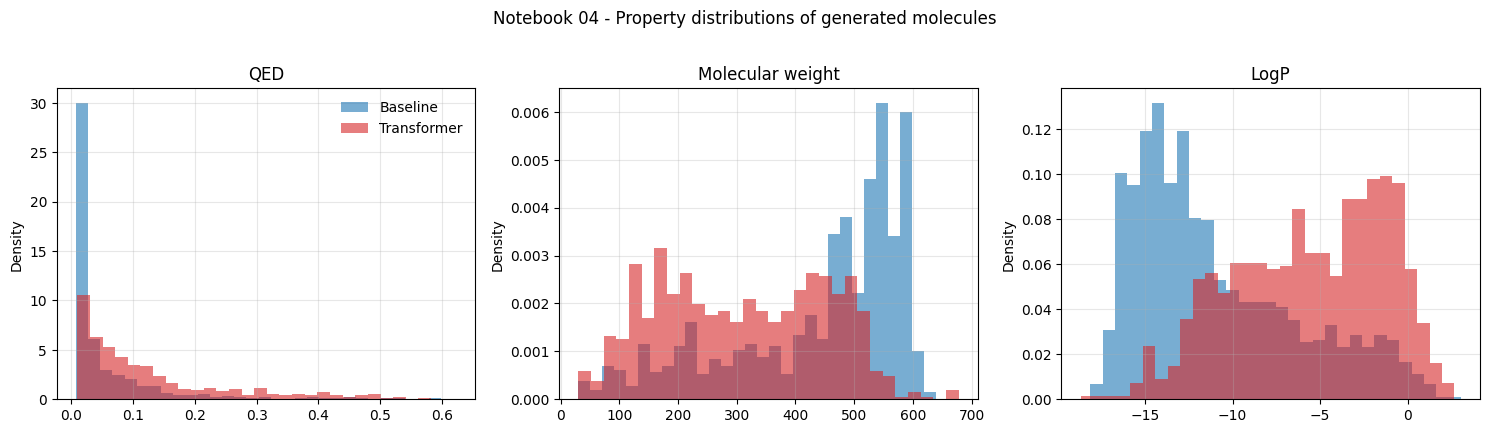

In [12]:
# Figure: property distributions of generated molecules
def _prop(smiles, key):
    out = []
    for s in set(smiles):
        e = evaluate_molecule(s)
        if e is not None:
            out.append(e[key])
    return out

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, key, title in zip(axes, ['QED', 'MW', 'LogP'],
                          ['QED', 'Molecular weight', 'LogP']):
    ax.hist(_prop(base_smiles, key), bins=30, alpha=0.6, density=True,
            label='Baseline', color='#1f77b4')
    ax.hist(_prop(tf_smiles, key), bins=30, alpha=0.6, density=True,
            label='Transformer', color='#d62728')
    ax.set_title(title); ax.set_ylabel('Density'); ax.grid(alpha=0.3)
axes[0].legend(frameon=False)
fig.suptitle('Notebook 04 - Property distributions of generated molecules', y=1.02)
fig.tight_layout()
fig.savefig('../results/figures/nb04_property_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

## Summary and how to read the results

This notebook adds an attention-based (transformer) encoder as a drop-in swap and compares it against the Notebook-03 baseline on identical data, decoder, loss and training schedule. Outputs written:

- `../models/graph_vae_transformer.pth` - trained transformer-VAE weights
- `../results/nb04_encoder_comparison.csv` - side-by-side metric table
- `../results/figures/nb04_encoder_architecture.png` - architecture schematic
- `../results/figures/nb04_training_comparison.png` - training curves
- `../results/figures/nb04_generation_metrics.png` - generative metrics
- `../results/figures/nb04_property_distributions.png` - property distributions

**Interpreting.** Lower reconstruction/total loss with comparable KL indicates the attention encoder learns a usable latent space; higher validity/uniqueness/diversity or QED indicates better downstream generation. Because Notebook 03 is unseeded, treat single-run differences cautiously and, for a publishable claim, average several seeded runs of both models.

**Scope.** This is the tier-1 (encoder-only) transformer. The full TGVAE (Nguyen & Karolak, 2025) additionally replaces the graph decoder with an autoregressive SMILES transformer - a substantially larger change suitable as future work.